# 4. Merge datasets → EU influenza weekly panel

Combines the three raw sources into **one analysis-ready table**.

**Scope: influenza only.** RSV, SARS-CoV-2 and ARI (acute respiratory infections, not influenza-specific) are left out.

| Source | Raw file(s) in `raw_data/` | What we take |
|---|---|---|
| ECDC ERVISS | `ecdc_*.csv` (or original names `ILIARIRates.csv`, …) | ILI and SARI rates; influenza tests / detections / positivity; influenza hospital & ICU admissions, deaths |
| WHO FluNet | `who_flunet.csv` (or `who_flunet_EU27.csv`) | influenza specimens tested and positive, by type/subtype |
| Eurostat `demo_r_mwk_20` | `eurostat_demo_r_mwk_20.csv` | all-cause weekly deaths by age, expected and excess deaths |

**Output** (in `raw_data/raw_final_joined/`):

- `eu_influenza_weekly.csv` – one row = **country × ISO week**, EU/EEA countries, from 2015-W01
- `eu_influenza_weekly_dictionary.csv` – description of every column

**Join key:** `country_code` (ISO 3166-1 alpha-2) + `year_week` (ISO 8601, e.g. `2024-W05`).

Run notebooks 1–3 first.

In [1]:
from pathlib import Path
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("raw_data")
OUT = RAW / "raw_final_joined"
OUT.mkdir(parents=True, exist_ok=True)

START_WEEK = "2015-W01"            # start of the panel (also start of the excess-mortality baseline)
BASELINE_YEARS = range(2015, 2020) # pre-COVID baseline for expected deaths

OUTPUT_FILE = OUT / "eu_influenza_weekly.csv"
DICTIONARY_FILE = OUT / "eu_influenza_weekly_dictionary.csv"

pd.set_option("display.max_columns", 60)
print("Run date:", datetime.date.today())

Run date: 2026-10-26


## 1. Reference tables and helpers

Each source codes countries differently: ECDC uses English names, WHO uses ISO3, and Eurostat uses ISO2 **except Greece = `EL`**. Everything is mapped to ISO2.

In [2]:
COUNTRIES = pd.DataFrame([
    # iso2, iso3, name,          eurostat_geo
    ("AT", "AUT", "Austria",     "AT"), ("BE", "BEL", "Belgium",    "BE"),
    ("BG", "BGR", "Bulgaria",    "BG"), ("HR", "HRV", "Croatia",    "HR"),
    ("CY", "CYP", "Cyprus",      "CY"), ("CZ", "CZE", "Czechia",    "CZ"),
    ("DK", "DNK", "Denmark",     "DK"), ("EE", "EST", "Estonia",    "EE"),
    ("FI", "FIN", "Finland",     "FI"), ("FR", "FRA", "France",     "FR"),
    ("DE", "DEU", "Germany",     "DE"), ("GR", "GRC", "Greece",     "EL"),
    ("HU", "HUN", "Hungary",     "HU"), ("IE", "IRL", "Ireland",    "IE"),
    ("IT", "ITA", "Italy",       "IT"), ("LV", "LVA", "Latvia",     "LV"),
    ("LT", "LTU", "Lithuania",   "LT"), ("LU", "LUX", "Luxembourg", "LU"),
    ("MT", "MLT", "Malta",       "MT"), ("NL", "NLD", "Netherlands","NL"),
    ("PL", "POL", "Poland",      "PL"), ("PT", "PRT", "Portugal",   "PT"),
    ("RO", "ROU", "Romania",     "RO"), ("SK", "SVK", "Slovakia",   "SK"),
    ("SI", "SVN", "Slovenia",    "SI"), ("ES", "ESP", "Spain",      "ES"),
    ("SE", "SWE", "Sweden",      "SE"),
    ("IS", "ISL", "Iceland",     "IS"), ("LI", "LIE", "Liechtenstein", "LI"),
    ("NO", "NOR", "Norway",      "NO"),
], columns=["country_code", "iso3", "country_name", "eurostat_geo"])
COUNTRIES["eu_member"] = ~COUNTRIES.country_code.isin(["IS", "LI", "NO"])

NAME_TO_ISO2 = dict(zip(COUNTRIES.country_name, COUNTRIES.country_code))
ISO3_TO_ISO2 = dict(zip(COUNTRIES.iso3, COUNTRIES.country_code))
GEO_TO_ISO2  = dict(zip(COUNTRIES.eurostat_geo, COUNTRIES.country_code))
COUNTRIES

,country_code,iso3,country_name,eurostat_geo,eu_member
0,AT,AUT,Austria,AT,True
1,BE,BEL,Belgium,BE,True
2,BG,BGR,Bulgaria,BG,True
3,HR,HRV,Croatia,HR,True
4,CY,CYP,Cyprus,CY,True
5,CZ,CZE,Czechia,CZ,True
6,DK,DNK,Denmark,DK,True
7,EE,EST,Estonia,EE,True
8,FI,FIN,Finland,FI,True
9,FR,FRA,France,FR,True


In [3]:
def week_start(year_week: pd.Series) -> pd.Series:
    """'2024-W05' -> Monday of that ISO week."""
    return pd.to_datetime(year_week.str.replace("-W", "-") + "-1", format="%G-%V-%u")

def to_year_week(dates: pd.Series) -> pd.Series:
    return dates.dt.strftime("%G-W%V")

def flu_season(iso_year: pd.Series, iso_week: pd.Series) -> pd.Series:
    """Influenza season runs from ISO week 40 to week 39 of the next year -> '2024/25'."""
    start = np.where(iso_week >= 40, iso_year, iso_year - 1)
    return pd.Series([f"{s}/{str(s + 1)[-2:]}" for s in start], index=iso_year.index)

def map_codes(series: pd.Series, mapping: dict, source: str) -> pd.Series:
    out = series.map(mapping)
    dropped = sorted(series[out.isna()].dropna().unique())
    if dropped:
        print(f"[{source}] not EU/EEA or unknown, dropped: {dropped}")
    return out

def read_first(*names) -> pd.DataFrame:
    for n in names:
        if (RAW / n).exists():
            print("reading", RAW / n)
            return pd.read_csv(RAW / n, low_memory=False)
    raise FileNotFoundError(f"None of {names} found in {RAW}/ – run notebooks 1–3 first.")

## 2. ECDC ERVISS

All files are in long format. We keep the **country totals** for each pathogen (plus influenza subtypes and age groups for rates) and pivot them to columns.

Column prefixes:
- `ili_rate`, `sari_rate`: consultation / admission rates (per 100,000, see dictionary for exceptions). ILI is the clinical proxy for influenza; SARI is the hospital burden of all severe respiratory infections.
- `sent_`: sentinel primary-care specimens · `sari_`: sentinel hospital (SARI) specimens · `lab_`: non-sentinel laboratory detections
- `flu_` + `hosp_admissions`, `icu_admissions`, `icu_inpatients`, `deaths`: severity (non-sentinel)

`activityFluTypeSubtype.csv` is not used: it repeats the subtype detections already in the sentinel and non-sentinel files. `variants.csv` and `sequencing…csv` are SARS-CoV-2 genomics and are out of scope.

In [4]:
PATHOGEN = {"Influenza": "flu", "RSV": "rsv", "SARS-CoV-2": "covid"}
FLU_SUBTYPE = {"A(H1)pdm09": "a_h1pdm09", "A(H3)": "a_h3", "A (unknown)": "a_unknown",
               "B/Vic": "b_vic", "B/Yam": "b_yam", "B (unknown)": "b_unknown",
               "Influenza untyped": "untyped"}
INDICATOR = {"tests": "tests", "detections": "detections", "positivity": "positivity",
             "ILIconsultationrate": "ili_rate", "ARIconsultationrate": "ari_rate", "SARIrate": "sari_rate",
             "hospitaladmissions": "hosp_admissions", "ICUadmissions": "icu_admissions",
             "ICUinpatients": "icu_inpatients", "deaths": "deaths"}
AGE = {"total": "", "0-4": "_age_0_4", "5-14": "_age_5_14", "15-64": "_age_15_64", "65+": "_age_65plus"}


def ecdc_rates(df):
    """ILI/ARI/SARI rates, all age groups."""
    df = df[df.age.isin(AGE)].copy()
    df["column"] = df.indicator.map(INDICATOR) + df.age.map(AGE)
    return df


def ecdc_virology(df, prefix):
    """Tests / detections / positivity per pathogen (age total) + influenza subtype detections."""
    df = df[df.age == "total"].copy()
    pat = df.pathogen.map(PATHOGEN)
    total = (df.pathogentype == df.pathogen) & (
        df.pathogensubtype.isna() | (df.pathogensubtype == "total") | (df.pathogensubtype == df.pathogen))
    sub = (df.pathogen == "Influenza") & df.pathogensubtype.isin(FLU_SUBTYPE)
    df.loc[total, "column"] = prefix + "_" + pat[total] + "_" + df.loc[total, "indicator"].map(INDICATOR)
    df.loc[sub, "column"] = prefix + "_flu_" + df.loc[sub, "pathogensubtype"].map(FLU_SUBTYPE) + "_detections"
    return df.dropna(subset=["column"])


def ecdc_severity(df):
    df = df[df.age == "total"].copy()
    df["column"] = df.pathogen.map(PATHOGEN) + "_" + df.indicator.map(INDICATOR)
    return df.dropna(subset=["column"])


ECDC_FILES = {
    "ILIARIRates":                       ecdc_rates,
    "SARIRates":                         ecdc_rates,
    "sentinelTestsDetectionsPositivity": lambda d: ecdc_virology(d, "sent"),
    "SARITestsDetectionsPositivity":     lambda d: ecdc_virology(d, "sari"),
    "nonSentinelTestsDetections":        lambda d: ecdc_virology(d, "lab"),
    "nonSentinelSeverity":               ecdc_severity,
}

parts = []
for name, transform in ECDC_FILES.items():
    raw = read_first(f"ecdc_{name}.csv", f"{name}.csv")
    # influenza only: drop RSV, SARS-CoV-2 and ARI rates
    if "pathogen" in raw.columns:
        raw = raw[raw.pathogen == "Influenza"]
    raw = raw[raw.indicator != "ARIconsultationrate"]
    t = transform(raw)
    t = t[["countryname", "yearweek", "column", "value"]]
    dup = t.duplicated(["countryname", "yearweek", "column"]).sum()
    assert dup == 0, f"{name}: {dup} duplicate keys"
    parts.append(t)
    print(f"   {name:36s} {len(raw):>7,} rows -> {t.column.nunique():>2} columns")

ecdc_long = pd.concat(parts)
ecdc_long["country_code"] = map_codes(ecdc_long.countryname, NAME_TO_ISO2, "ECDC")
ecdc = (ecdc_long.dropna(subset=["country_code"])
        .pivot_table(index=["country_code", "yearweek"], columns="column", values="value", aggfunc="first")
        .reset_index().rename(columns={"yearweek": "year_week"}))
ecdc.columns.name = None
print("ECDC wide:", ecdc.shape, "|", ecdc.year_week.min(), "->", ecdc.year_week.max())

reading raw_data/ecdc_ILIARIRates.csv
   ILIARIRates                           20,610 rows ->  5 columns
reading raw_data/ecdc_SARIRates.csv
   SARIRates                             11,074 rows ->  5 columns
reading raw_data/ecdc_sentinelTestsDetectionsPositivity.csv
   sentinelTestsDetectionsPositivity     22,101 rows -> 10 columns
reading raw_data/ecdc_SARITestsDetectionsPositivity.csv
   SARITestsDetectionsPositivity         11,033 rows ->  9 columns
reading raw_data/ecdc_nonSentinelTestsDetections.csv
   nonSentinelTestsDetections            25,821 rows ->  8 columns
reading raw_data/ecdc_nonSentinelSeverity.csv
   nonSentinelSeverity                   14,774 rows ->  3 columns
[ECDC] not EU/EEA or unknown, dropped: ['EU/EEA']
ECDC wide: (6499, 42) | 2022-W25 -> 2026-W42


In [ ]:
ecdc.filter(regex="country|week|ili_rate$|sent_flu_|flu_hosp").head()

## 3. WHO FluNet

A country reports up to three rows per week, one per `ORIGIN_SOURCE` (`SENTINEL`, `NONSENTINEL`, `NOTDEFINED`).

> ⚠️ Known issue left for the cleaning step: `INF_ALL` is often empty although `INF_A` / `INF_B` are filled. It is **not** fixed here.

**Non-sentinel testing is targeted** (mostly suspected cases), so its positivity is biased upwards, especially in summer. WHO marks the *preferred source for positivity* in `PSOURCE_PPOS_INF`; this is the sentinel system.

So we keep:
- `who_flu_*`: counts **summed over all sources** (total volume of tests and detections),
- `who_sent_flu_*`: counts from the **preferred / sentinel source only**,
- `who_sent_flu_positivity`: positivity from the sentinel source; set to missing when fewer than `MIN_TESTS` specimens were tested (too noisy).

In [5]:
MIN_TESTS = 10   # minimum specimens tested to report positivity

who_raw = read_first("who_flunet.csv", "who_flunet_EU27.csv")
who_raw["country_code"] = map_codes(who_raw.COUNTRY_CODE, ISO3_TO_ISO2, "WHO")
who_raw = who_raw.dropna(subset=["country_code"]).copy()
who_raw["year_week"] = who_raw.ISO_YEAR.astype(int).astype(str) + "-W" + who_raw.ISO_WEEK.astype(int).astype(str).str.zfill(2)

# B/Victoria is split into several deletion columns (BVIC_2DEL, BVIC_3DEL, ...)
bvic_cols = [c for c in who_raw.columns if c.startswith("BVIC")]
who_raw["BVIC_ALL"] = who_raw[bvic_cols].sum(axis=1, min_count=1) if bvic_cols else np.nan

# preferred source for positivity (WHO recommendation); fall back to ORIGIN_SOURCE == SENTINEL
if "PSOURCE_PPOS_INF" in who_raw.columns:
    who_raw["is_preferred"] = who_raw.PSOURCE_PPOS_INF.eq(1)
else:
    who_raw["is_preferred"] = who_raw.ORIGIN_SOURCE.eq("SENTINEL")
print(pd.crosstab(who_raw.ORIGIN_SOURCE, who_raw.is_preferred))

WHO_COLUMNS = {
    "SPEC_PROCESSED_NB": "flu_tests",
    "INF_ALL": "flu_detections",
    "INF_A": "flu_a_detections",
    "INF_B": "flu_b_detections",
    "AH1N12009": "flu_a_h1pdm09_detections",
    "AH3": "flu_a_h3_detections",
    "BVIC_ALL": "flu_b_vic_detections",
    "BYAM": "flu_b_yam_detections",
}
available = {k: v for k, v in WHO_COLUMNS.items() if k in who_raw.columns}
missing = set(WHO_COLUMNS) - set(available)
if missing:
    print("WHO columns not found (check the data dictionary):", missing)

def who_aggregate(df, prefix, cols):
    out = df.groupby(["country_code", "year_week"])[cols].sum(min_count=1)
    return out.rename(columns={k: f"{prefix}_{available[k]}" for k in cols})

who_all = who_aggregate(who_raw, "who", list(available))
who_sent = who_aggregate(who_raw[who_raw.is_preferred], "who_sent", ["SPEC_PROCESSED_NB", "INF_ALL", "INF_A", "INF_B"])
who = who_all.join(who_sent, how="outer").reset_index()

ok = who.who_sent_flu_tests >= MIN_TESTS
who["who_sent_flu_positivity"] = (100 * who.who_sent_flu_detections / who.who_sent_flu_tests).where(ok).round(2)
who = who[who.year_week >= START_WEEK]
print("WHO wide:", who.shape, "|", who.year_week.min(), "->", who.year_week.max())
who[who.country_code == "SK"].tail()

reading raw_data/who_flunet.csv
[WHO] not EU/EEA or unknown, dropped: ['ABW', 'AFG', 'AGO', 'AIA', 'ALB', 'ARE', 'ARG', 'ARM', 'ATG', 'AUS', 'AZE', 'BFA', 'BGD', 'BHR', 'BHS', 'BIH', 'BLM', 'BLR', 'BLZ', 'BMU', 'BOL', 'BRA', 'BRB', 'BRN', 'BTN', 'CAF', 'CAN', 'CHE', 'CHL', 'CHN', 'CIV', 'CMR', 'COD', 'COG', 'COL', 'CRI', 'CUB', 'CYM', 'DMA', 'DOM', 'DZA', 'ECU', 'EGY', 'ETH', 'FJI', 'GAB', 'GEO', 'GHA', 'GIN', 'GLP', 'GRD', 'GTM', 'GUF', 'GUY', 'HKG', 'HND', 'HTI', 'IDN', 'IND', 'IRN', 'IRQ', 'ISR', 'JAM', 'JOR', 'JPN', 'KAZ', 'KEN', 'KGZ', 'KHM', 'KNA', 'KOR', 'KWT', 'LAO', 'LBN', 'LBR', 'LBY', 'LCA', 'LKA', 'LSO', 'MAF', 'MAR', 'MDA', 'MDG', 'MDV', 'MEX', 'MKD', 'MLI', 'MMR', 'MNE', 'MNG', 'MOZ', 'MRT', 'MSR', 'MTQ', 'MUS', 'MYS', 'NAM', 'NCL', 'NER', 'NGA', 'NIC', 'NPL', 'NZL', 'OMN', 'PAK', 'PAN', 'PER', 'PHL', 'PNG', 'PRK', 'PRY', 'PSE', 'QAT', 'RUS', 'RWA', 'SAU', 'SCG', 'SDN', 'SEN', 'SGP', 'SLE', 'SLV', 'SOM', 'SRB', 'SSD', 'SUR', 'SYC', 'SYR', 'TCA', 'TCD', 'TGO', 'THA', 'TJK'

,country_code,year_week,who_flu_tests,who_flu_detections,who_flu_a_detections,who_flu_b_detections,who_flu_a_h1pdm09_detections,who_flu_a_h3_detections,who_flu_b_vic_detections,who_flu_b_yam_detections,who_sent_flu_tests,who_sent_flu_detections,who_sent_flu_a_detections,who_sent_flu_b_detections,who_sent_flu_positivity
31311,SK,2026-W38,9.0,4.0,2.0,2.0,NaN,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN
31312,SK,2026-W39,21.0,4.0,4.0,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN
31313,SK,2026-W40,17.0,6.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
31314,SK,2026-W41,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN,NaN
31315,SK,2026-W42,22.0,12.0,12.0,NaN,NaN,NaN,NaN,NaN,8.0,3.0,3.0,NaN,NaN


## 4. Eurostat weekly deaths + excess mortality

- Drop week `W99` (deaths with unknown week).
- Keep both sexes (`sex == "T"`), all age groups.
- **Expected deaths** = mean deaths in the same ISO week of 2015–2019 for that country (week 53 uses the week-52 baseline).
- **Excess deaths** = observed − expected. Recent weeks are provisional (flag `p`) and usually still incomplete.

In [6]:
eus_raw = read_first("eurostat_demo_r_mwk_20.csv", "eurostat_umrtia_tyzdenne.csv")
eus_raw = eus_raw[eus_raw.TIME_PERIOD.str.match(r"^\d{4}-W\d{2}$") & ~eus_raw.TIME_PERIOD.str.endswith("W99")]
eus_raw = eus_raw[(eus_raw.sex == "T") & (eus_raw.unit == "NR")]
eus_raw["country_code"] = map_codes(eus_raw.geo, GEO_TO_ISO2, "Eurostat")
eus_raw = eus_raw.dropna(subset=["country_code"]).rename(columns={"TIME_PERIOD": "year_week"})

AGE_EUS = {"TOTAL": "deaths_total", "Y_LT20": "deaths_age_0_19", "Y20-39": "deaths_age_20_39",
           "Y40-59": "deaths_age_40_59", "Y60-79": "deaths_age_60_79", "Y_GE80": "deaths_age_80plus"}
eus = (eus_raw[eus_raw.age.isin(AGE_EUS)]
       .assign(column=lambda d: d.age.map(AGE_EUS))
       .pivot_table(index=["country_code", "year_week"], columns="column", values="OBS_VALUE", aggfunc="first")
       .reset_index())
eus.columns.name = None
eus = eus[["country_code", "year_week"] + [c for c in AGE_EUS.values() if c in eus.columns]]

# provisional flag for the total
if "OBS_FLAG" in eus_raw.columns:
    flag = eus_raw[eus_raw.age == "TOTAL"].set_index(["country_code", "year_week"]).OBS_FLAG
    eus = eus.merge(flag.fillna("").str.contains("p").rename("deaths_provisional").reset_index(),
                    on=["country_code", "year_week"], how="left")
else:
    eus["deaths_provisional"] = False

# expected & excess deaths
iso = week_start(eus.year_week).dt.isocalendar()
eus["_year"], eus["_week"] = iso.year.values, iso.week.clip(upper=52).values
baseline = (eus[eus._year.isin(BASELINE_YEARS)]
            .groupby(["country_code", "_week"]).deaths_total.mean().rename("expected_deaths").reset_index())
eus = eus.merge(baseline, on=["country_code", "_week"], how="left").drop(columns=["_year", "_week"])
eus["expected_deaths"] = eus.expected_deaths.round(1)
eus["excess_deaths"] = (eus.deaths_total - eus.expected_deaths).round(1)
eus["excess_deaths_pct"] = (100 * eus.excess_deaths / eus.expected_deaths).round(2)
eus = eus[eus.year_week >= START_WEEK]
print("Eurostat wide:", eus.shape, "|", eus.year_week.min(), "->", eus.year_week.max())
eus.tail()

reading raw_data/eurostat_demo_r_mwk_20.csv
[Eurostat] not EU/EEA or unknown, dropped: ['AD', 'AL', 'AM', 'CH', 'EU27_2020', 'GE', 'ME', 'RS', 'UK']
Eurostat wide: (18025, 12) | 2015-W01 -> 2026-W32


,country_code,year_week,deaths_total,deaths_age_0_19,deaths_age_20_39,deaths_age_40_59,deaths_age_60_79,deaths_age_80plus,deaths_provisional,expected_deaths,excess_deaths,excess_deaths_pct
18020,SK,2026-W23,923.0,12.0,16.0,87.0,419.0,389.0,True,922.2,0.8,0.09
18021,SK,2026-W24,909.0,7.0,14.0,96.0,417.0,375.0,True,972.2,-63.2,-6.50
18022,SK,2026-W25,933.0,9.0,15.0,101.0,426.0,382.0,True,955.2,-22.2,-2.32
18023,SK,2026-W26,1090.0,11.0,27.0,106.0,515.0,431.0,True,926.6,163.4,17.63
18024,SK,2026-W27,1152.0,3.0,22.0,145.0,512.0,470.0,True,937.4,214.6,22.89


## 5. Join into one panel

1. Build a complete **country × week** grid (all EU/EEA countries, every ISO week from `START_WEEK` to the latest week in any source).
2. `left join` ECDC, WHO and Eurostat onto the grid.
3. Add calendar columns (`week_start`, `iso_year`, `iso_week`, `season`, `season_week`) and source-availability flags.
4. Drop country-weeks with no data in any source.

In [7]:
last_week = max(ecdc.year_week.max(), who.year_week.max(), eus.year_week.max())
mondays = pd.date_range(week_start(pd.Series([START_WEEK]))[0], week_start(pd.Series([last_week]))[0], freq="W-MON")
grid = pd.MultiIndex.from_product([COUNTRIES.country_code, to_year_week(pd.Series(mondays))],
                                  names=["country_code", "year_week"]).to_frame(index=False)

panel = (grid
         .merge(ecdc, on=["country_code", "year_week"], how="left")
         .merge(who,  on=["country_code", "year_week"], how="left")
         .merge(eus,  on=["country_code", "year_week"], how="left"))

panel["has_ecdc"] = panel[ecdc.columns.drop(["country_code", "year_week"])].notna().any(axis=1)
panel["has_who"] = panel[who.columns.drop(["country_code", "year_week"])].notna().any(axis=1)
panel["has_eurostat"] = panel["deaths_total"].notna()
panel = panel[panel.has_ecdc | panel.has_who | panel.has_eurostat].copy()

panel["week_start"] = week_start(panel.year_week)
iso = panel.week_start.dt.isocalendar()
panel["iso_year"], panel["iso_week"] = iso.year.astype(int).values, iso.week.astype(int).values
panel["season"] = flu_season(panel.iso_year, panel.iso_week)
panel["season_week"] = ((panel.week_start - week_start(panel.season.str[:4] + "-W40")).dt.days // 7 + 1).astype(int)
panel = panel.merge(COUNTRIES[["country_code", "country_name", "eu_member"]], on="country_code", how="left")
panel["deaths_provisional"] = panel["deaths_provisional"].astype("boolean")

KEYS = ["country_code", "country_name", "eu_member", "year_week", "week_start", "iso_year", "iso_week",
        "season", "season_week", "has_ecdc", "has_who", "has_eurostat"]
ecdc_cols = sorted(ecdc.columns.drop(["country_code", "year_week"]),
                   key=lambda c: (not c.endswith("_rate") and "_rate_" not in c, c))
who_cols = list(who.columns.drop(["country_code", "year_week"]))
eus_cols = list(eus.columns.drop(["country_code", "year_week"]))
panel = panel[KEYS + ecdc_cols + who_cols + eus_cols].sort_values(["country_code", "week_start"]).reset_index(drop=True)

assert not panel.duplicated(["country_code", "year_week"]).any(), "duplicate country-week rows!"
print(panel.shape)
panel.head()

(18456, 75)


,country_code,country_name,eu_member,year_week,week_start,iso_year,iso_week,season,season_week,has_ecdc,has_who,has_eurostat,ili_rate,ili_rate_age_0_4,ili_rate_age_15_64,ili_rate_age_5_14,ili_rate_age_65plus,sari_rate,sari_rate_age_0_4,sari_rate_age_15_64,sari_rate_age_5_14,sari_rate_age_65plus,flu_deaths,flu_hosp_admissions,flu_icu_admissions,lab_flu_a_h1pdm09_detections,lab_flu_a_h3_detections,lab_flu_a_unknown_detections,lab_flu_b_unknown_detections,lab_flu_b_vic_detections,...,sent_flu_b_unknown_detections,sent_flu_b_vic_detections,sent_flu_b_yam_detections,sent_flu_detections,sent_flu_positivity,sent_flu_tests,sent_flu_untyped_detections,who_flu_tests,who_flu_detections,who_flu_a_detections,who_flu_b_detections,who_flu_a_h1pdm09_detections,who_flu_a_h3_detections,who_flu_b_vic_detections,who_flu_b_yam_detections,who_sent_flu_tests,who_sent_flu_detections,who_sent_flu_a_detections,who_sent_flu_b_detections,who_sent_flu_positivity,deaths_total,deaths_age_0_19,deaths_age_20_39,deaths_age_40_59,deaths_age_60_79,deaths_age_80plus,deaths_provisional,expected_deaths,excess_deaths,excess_deaths_pct
0,AT,Austria,True,2015-W01,2014-12-29,2015,1,2014/15,14,False,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.0,7.0,7.0,0.0,0.0,3.0,0.0,0.0,3.0,1.0,1.0,0.0,NaN,1693.0,9.0,18.0,114.0,523.0,1029.0,False,1807.0,-114.0,-6.31
1,AT,Austria,True,2015-W02,2015-01-05,2015,2,2014/15,15,False,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,214.0,41.0,39.0,2.0,1.0,8.0,0.0,0.0,15.0,6.0,6.0,0.0,40.00,1768.0,9.0,9.0,144.0,558.0,1048.0,False,1857.2,-89.2,-4.80
2,AT,Austria,True,2015-W03,2015-01-12,2015,3,2014/15,16,False,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,82.0,74.0,8.0,9.0,22.0,0.0,0.0,33.0,16.0,12.0,4.0,48.48,1837.0,13.0,20.0,130.0,594.0,1080.0,False,1786.6,50.4,2.82
3,AT,Austria,True,2015-W04,2015-01-19,2015,4,2014/15,17,False,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,523.0,195.0,183.0,12.0,16.0,67.0,0.0,0.0,52.0,32.0,30.0,2.0,61.54,1792.0,13.0,22.0,127.0,557.0,1073.0,False,1747.2,44.8,2.56
4,AT,Austria,True,2015-W05,2015-01-26,2015,5,2014/15,18,False,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,403.0,171.0,152.0,19.0,20.0,98.0,0.0,0.0,92.0,59.0,55.0,4.0,64.13,1837.0,12.0,18.0,143.0,566.0,1098.0,False,1818.8,18.2,1.00


## 6. Quality checks

In [8]:
# coverage of each source per country
def span(flag):
    return panel[panel[flag]].groupby("country_code").year_week.agg(["min", "max", "count"])

coverage = pd.concat({"ECDC": span("has_ecdc"), "WHO": span("has_who"), "Eurostat": span("has_eurostat")}, axis=1)
coverage

ECDC                       WHO                  Eurostat  \
                   min       max count       min       max count       min   
country_code                                                                 
AT            2022-W40  2026-W42   207  2015-W01  2026-W42   473  2015-W01   
BE            2022-W25  2026-W42   226  2015-W01  2026-W42   574  2015-W01   
BG            2022-W25  2026-W42   222  2015-W01  2026-W42   606  2015-W01   
CY            2024-W01  2026-W41   145  2016-W01  2026-W41   418  2015-W01   
CZ            2022-W25  2026-W42   226  2015-W01  2026-W42   500  2015-W01   
DE            2022-W25  2026-W41   225  2015-W01  2026-W40   611  2015-W01   
DK            2022-W25  2026-W42   226  2015-W01  2026-W42   614  2015-W01   
EE            2022-W25  2026-W42   226  2015-W01  2026-W42   593  2015-W01   
ES            2022-W25  2026-W42   226  2015-W01  2026-W42   576  2015-W01   
FI            2022-W25  2026-W42   226  2015-W01  2026-W42   616  2015-W01   
FR            2022-W25  2026-W42   226  2015-W01  2026-W42   503  2015-W01   
GR            2022-W25  2026-W42   226  2015-W01  2026-W42   526  2015-W01   
HR            2022-W25  2026-W41   225  2015-W01  2026-W41   481  2015-W01   
HU            2022-W40  2026-W42   190  2015-W01  2026-W42   506  2015-W01   
IE            2022-W25  2026-W42   226  2015-W01  2026-W42   613  2015-W01   
IS            2022-W25  2026-W42   226  2015-W01  2026-W42   615  2015-W01   
IT            2022-W25  2026-W24   129  2015-W01  2026-W09   400  2015-W01   
LI            2022-W25  2026-W42   222  2020-W25  2026-W42   328  2015-W01   
LT            2022-W25  2026-W42   226  2015-W01  2026-W39   587  2015-W01   
LU            2022-W25  2026-W42   226  2015-W01  2026-W42   504  2015-W01   
LV            2022-W25  2026-W42   200  2015-W01  2026-W40   505  2015-W01   
MT            2022-W25  2026-W42   226  2015-W01  2026-W42   520  2015-W01   
NL            2022-W25  2026-W42   226  2015-W01  2026-W42   616  2015-W01   
NO            2022-W25  2026-W42   226  2015-W01  2026-W42   616  2015-W01   
PL            2022-W25  2026-W41   221  2015-W01  2026-W41   609  2015-W01   
PT            2022-W25  2026-W41   224  2015-W01  2026-W41   568  2015-W01   
RO            2022-W25  2026-W42   221  2015-W01  2026-W42   553  2015-W01   
SE            2022-W25  2026-W42   226  2015-W01  2026-W42   615  2015-W01   
SI            2022-W25  2026-W42   226  2015-W01  2026-W42   616  2015-W01   
SK            2022-W25  2026-W42   226  2015-W01  2026-W42   616  2015-W01   

                              
                   max count  
country_code                  
AT            2026-W28   602  
BE            2026-W27   601  
BG            2026-W27   601  
CY            2026-W27   601  
CZ            2026-W27   601  
DE            2026-W27   601  
DK            2026-W26   600  
EE            2026-W27   601  
ES            2026-W27   601  
FI            2026-W32   606  
FR            2026-W28   602  
GR            2026-W27   601  
HR            2026-W27   601  
HU            2026-W27   601  
IE            2026-W27   601  
IS            2026-W27   601  
IT            2026-W27   601  
LI            2026-W28   602  
LT            2026-W27   601  
LU            2026-W27   601  
LV            2026-W28   602  
MT            2026-W28   602  
NL            2026-W27   601  
NO            2026-W27   601  
PL            2026-W27   601  
PT            2026-W27   601  
RO            2026-W26   588  
SE            2026-W26   600  
SI            2026-W27   601  
SK            2026-W27   601

In [9]:
# share of missing values per column (ECDC period only, since ECDC starts in 2022)
recent = panel[panel.year_week >= "2022-W25"]
missing = recent.drop(columns=KEYS).isna().mean().sort_values().mul(100).round(1)
missing.to_frame("missing_%_since_2022W25")

,missing_%_since_2022W25
excess_deaths_pct,6.4
expected_deaths,6.4
deaths_provisional,6.4
deaths_total,6.4
excess_deaths,6.4
...,...
lab_flu_untyped_detections,93.7
sari_flu_b_unknown_detections,95.0
sent_flu_untyped_detections,97.2
sari_flu_b_vic_detections,98.6


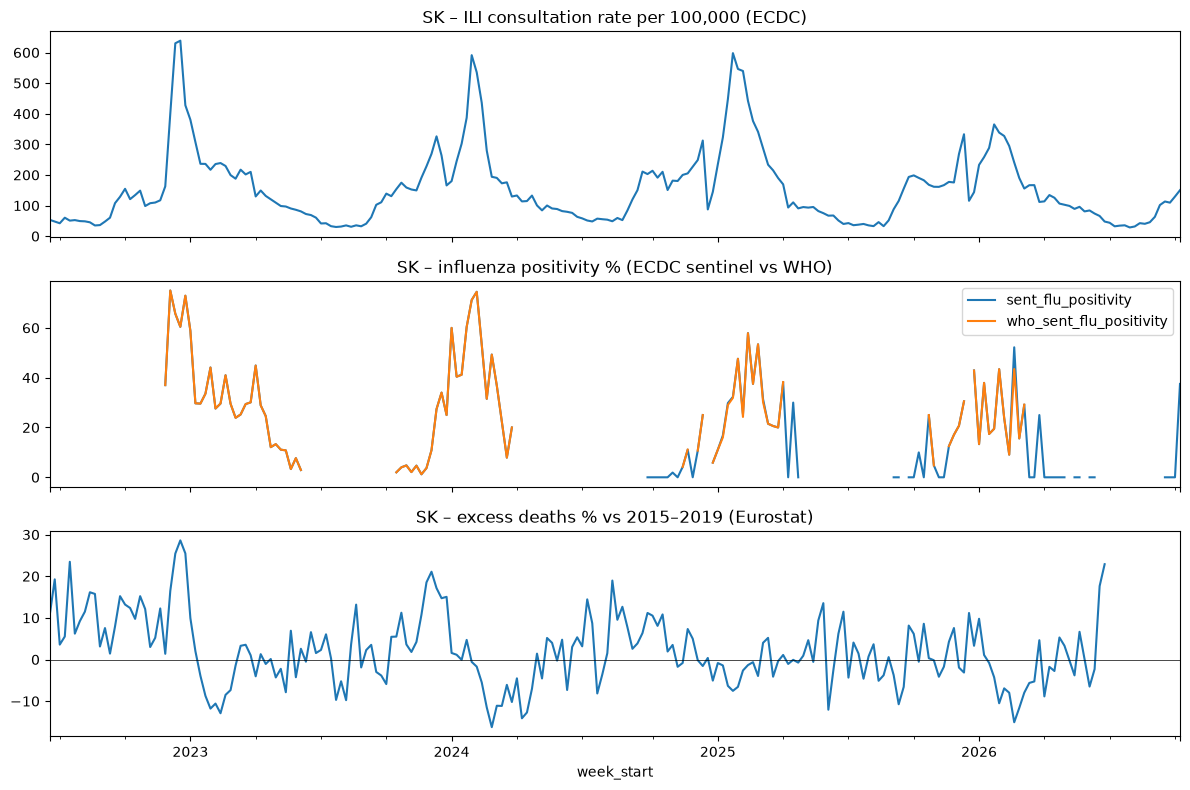

In [10]:
# Slovakia: ECDC ILI rate vs WHO influenza positivity vs excess deaths
sk = panel[(panel.country_code == "SK") & (panel.year_week >= "2022-W25")].set_index("week_start")
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
sk.ili_rate.plot(ax=ax[0], title="SK – ILI consultation rate per 100,000 (ECDC)")
sk[["sent_flu_positivity", "who_sent_flu_positivity"]].plot(ax=ax[1], title="SK – influenza positivity % (ECDC sentinel vs WHO)")
sk.excess_deaths_pct.plot(ax=ax[2], title="SK – excess deaths % vs 2015–2019 (Eurostat)")
ax[2].axhline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

## 7. Save the final dataset and data dictionary

In [11]:
def describe(col):
    fixed = {
        "country_code": "ISO 3166-1 alpha-2 country code (Greece = GR)",
        "country_name": "Country name (English)",
        "eu_member": "True for EU27, False for Iceland, Liechtenstein, Norway",
        "year_week": "ISO 8601 week, e.g. 2024-W05 (join key)",
        "week_start": "Monday of the ISO week",
        "iso_year": "ISO year", "iso_week": "ISO week number (1–53)",
        "season": "Influenza season, ISO week 40 to week 39 of the next year, e.g. 2024/25",
        "season_week": "Week of the influenza season (week 40 = 1)",
        "has_ecdc": "Row has at least one ECDC value", "has_who": "Row has at least one WHO FluNet value",
        "has_eurostat": "Row has Eurostat deaths",
        "ili_rate": "ECDC – influenza-like illness consultations per 100,000 population (CY, LU, MT: per 100 consultations; FI: per 100,000 consultations)",
        "ari_rate": "ECDC – acute respiratory infection consultations per 100,000 population (same exceptions as ILI)",
        "sari_rate": "ECDC – severe acute respiratory infection hospital admissions per 100,000 population",
        "who_sent_flu_positivity": "WHO FluNet preferred (sentinel) source – influenza detections / specimens tested, %; missing if fewer than MIN_TESTS (10) specimens",
        "deaths_provisional": "Eurostat – total deaths value is provisional (flag p)",
        "expected_deaths": "Mean all-cause deaths in the same ISO week, 2015–2019 (week 53 uses week 52)",
        "excess_deaths": "deaths_total − expected_deaths",
        "excess_deaths_pct": "excess_deaths / expected_deaths × 100",
    }
    if col in fixed:
        return fixed[col]
    base = col
    age = ""
    for code, label in [("_age_0_4", "0–4"), ("_age_5_14", "5–14"), ("_age_15_64", "15–64"), ("_age_65plus", "65+")]:
        if col.endswith(code):
            base, age = col[: -len(code)], f", age {label}"
    if base in fixed:
        return fixed[base] + age
    if col.startswith("deaths_"):
        return "Eurostat – all-cause deaths, " + col.replace("deaths_", "").replace("age_", "age ").replace("_", "–").replace("plus", "+")
    src = {"sent": "ECDC sentinel primary care specimens", "sari": "ECDC sentinel SARI (hospital) specimens",
           "lab": "ECDC non-sentinel laboratory", "who": "WHO FluNet, all sources summed",
           "whosent": "WHO FluNet, preferred (sentinel) source"}
    if col.startswith("who_sent_"):
        col = "whosent_" + col[len("who_sent_"):]
    p = col.split("_")[0]
    pathogen = {"flu": "influenza", "rsv": "RSV", "covid": "SARS-CoV-2"}
    measure = {"tests": "number of specimens tested", "detections": "number of positive detections",
               "positivity": "positivity %", "hosp_admissions": "hospital admissions",
               "icu_admissions": "ICU admissions", "icu_inpatients": "ICU inpatients", "deaths": "deaths"}
    for m, mtxt in measure.items():
        if col.endswith(m):
            middle = col[: -len(m) - 1]
            if p in src:
                middle = middle[len(p) + 1:]
                prefix = src[p]
            else:
                prefix = "ECDC non-sentinel severity"
            parts = middle.split("_", 1)
            what = pathogen.get(parts[0], parts[0])
            if len(parts) > 1:
                sub_label = {"a": "A", "b": "B", "a_h1pdm09": "A(H1)pdm09", "a_h3": "A(H3)",
                             "a_unknown": "A (subtype unknown)", "b_vic": "B/Victoria", "b_yam": "B/Yamagata",
                             "b_unknown": "B (lineage unknown)", "untyped": "untyped"}
                what += " " + sub_label.get(parts[1], parts[1])
            return f"{prefix} – {what}, {mtxt}"
    return ""

dictionary = pd.DataFrame({
    "column": panel.columns,
    "dtype": panel.dtypes.astype(str).values,
    "source": ["key" if c in KEYS else "ECDC ERVISS" if c in ecdc_cols else "WHO FluNet" if c in who_cols else "Eurostat demo_r_mwk_20"
               for c in panel.columns],
    "description": [describe(c) for c in panel.columns],
    "non_missing": panel.notna().sum().values,
})

panel.to_csv(OUTPUT_FILE, index=False)
dictionary.to_csv(DICTIONARY_FILE, index=False)
print(f"Saved {OUTPUT_FILE}  ({len(panel):,} rows × {panel.shape[1]} columns, "
      f"{OUTPUT_FILE.stat().st_size / 1e6:.1f} MB)")
print(f"Saved {DICTIONARY_FILE}")
dictionary

Saved raw_data/raw_final_joined/eu_influenza_weekly.csv  (18,456 rows × 75 columns, 4.2 MB)
Saved raw_data/raw_final_joined/eu_influenza_weekly_dictionary.csv


,column,dtype,source,description,non_missing
0,country_code,str,key,ISO 3166-1 alpha-2 country code (Greece = GR),18456
1,country_name,str,key,Country name (English),18456
2,eu_member,bool,key,"True for EU27, False for Iceland, Liechtenstei...",18456
3,year_week,str,key,"ISO 8601 week, e.g. 2024-W05 (join key)",18456
4,week_start,datetime64[us],key,Monday of the ISO week,18456
...,...,...,...,...,...
70,deaths_age_80plus,float64,Eurostat demo_r_mwk_20,"Eurostat – all-cause deaths, age 80+",17372
71,deaths_provisional,boolean,Eurostat demo_r_mwk_20,Eurostat – total deaths value is provisional (...,18025
72,expected_deaths,float64,Eurostat demo_r_mwk_20,"Mean all-cause deaths in the same ISO week, 20...",18025
73,excess_deaths,float64,Eurostat demo_r_mwk_20,deaths_total − expected_deaths,18025


### Loading the final dataset in other notebooks

```python
df = pd.read_csv("raw_data/raw_final_joined/eu_influenza_weekly.csv", parse_dates=["week_start"])
sk = df[df.country_code == "SK"]
```